# Chapter 6: Builder's Guide

* Just as chip designers went from specifying transistors to logical circuits writing code, neural network researchers moved from thinking about individual neurons to networks in whole layers, where design choices are made with much coarser blocks
* So far, have implemented MLP from scratch & high-level API versions
* This chapter will cover more advanced details about how the library works such as:
    * Model Construction
    * Parameter access & initialization
    * Designing custom blocks & layers
    * Reading models to disk
    * Leveraging GPUs for speedups

# 6.1 Layers and Modules

* Concept of _module_, which could describe a single layer, component consisting of multiple layers, or model itself
* Whole point is module abstractino can be combined into larger, more compelx structures
* Represent them in code as a _class_ (as we have before)
    * Define forward propogation method that transforms input to output
    * Store any necessary parameters (some modules may not need any parameters)
    * Backpropogation method for calculating gradients (autograd takes care of this)


* Below is a demo of _nn.Sequential_, with layers in order that should be executed passed as arguments. It is a special type of module. Note that nn.LazyLinear and nn.ReLU are also child classes of _Module_
* Previously have used net(X) to get outputs. Note that this is a shorthand for net.__call__(X)

In [3]:
import torch
from torch import nn
from torch.nn import functional as F

In [7]:
# Generate a network with 1 hidden linear layer with 256 neurons and ReLU activation, followed by 
# output layer with 10 neuron (no activation function)

net = nn.Sequential(nn.LazyLinear(256), nn.ReLU(), nn.LazyLinear(10))

X = torch.rand(2, 20)
net(X).shape
# output of 2 x 10 is for 10 classes and 2 examples in the batch

torch.Size([2, 10])

### 6.1.1 A Custom Module

Implement a module ourselves that must have the following basic functionalities:
1. Ingest input data as arguments to forward propogation method
2. Generate an output by having forward propogation method return a value. Note output shape dosen't have to be same as input shape (fully-connected layer)
3. Calculate gradient of output w.r.t. input that can be accessed via backpropogation method (note this is typically done automatically)
4. Store & provide access to parameters necessary for executing forward propogation method
5. Initialize model parameters (as needed)


In [8]:
# Code module of MLP w/ 1 hidden with 256 neurons and 10 dim outout payer
# inherits class that represents module and will be relying on parent's class's methods, thus
# we will only specify the __init__ and forward methods (latter must always be implemented ourself and overrise default)
# https://docs.pytorch.org/docs/2.12/generated/torch.nn.Module.html 

# Note - both layers are instance variables, which is reasonable since if we were to instantiatate two MLP
# instances, we would want and expect them to have different parameters

# Generally don't have to worrk about parameter initailization or backprop, as that is taken care of automatically

class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = nn.LazyLinear(256)
        self.out    = nn.LazyLinear(10)

    def forward(self, X):
        return self.out(F.relu(self.hidden(X)))
    
net = MLP()
net(X).shape

torch.Size([2, 10])

### 6.1.2 The Sequential Module

* _nn.Sequential_ is for daisy-chaining other modules together. 
* To build our own _Sequential_ class we just need 2 methods:
    1. A method for appending modules one by one to a list (order matters here)
    2. Forward propogation method for passing an input through the chain of modules, in the exact order they were appended

In [16]:
class MySequential(nn.Module):
    """ 
    Will have same functionality as nn.Sequential
    """
    def __init__(self, *args):
        super().__init__()
        for idx, module in enumerate(args):
            self.add_module(str(idx), module)

    def forward(self, X):
        for module in self.children():
            X = module(X)
        return X
    
# Note, add_module is inherited from nn.Module: https://docs.pytorch.org/docs/2.12/generated/torch.nn.Module.html

# Need children method, NOT modules method since latter is ALL modules in network, we are only 
# interested in child modules as that is what add_module method will add said module to parent 
# module (as a child module)

net = MySequential(nn.LazyLinear(256), nn.ReLU(), nn.LazyLinear(10))
net(X).shape

torch.Size([2, 10])

### 6.1.3 Executing Code in the Forward Propagation Method

* Some architectures are not simple daisy-chains 
    * We may want to execute Python's own control flow within forward method
    * We may want to perform arbitrary math operations, instead of relying on predefined neural network layers

Example: We may want operations with _constant parameters_ (i.e. not updated during optimizaiton/learning), such as implemented in _FixedHiddenMLP_ below

In [ ]:
# NOTE: torch.rand is NOT a model parameter and thus is updated during backpropogation, thus 'fixed'

class FixedHiddenMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.rand_weight = torch.rand( (20, 20) )
        self.linear = nn.LazyLinear(20)

    def forward(self, X):
        X = self.linear(X)
        X = F.relu(X @ self.rand_weight + 1)
        X = self.linear(X)

        # Custom python control flow demo within forward method. Not actually used in practice, 
        # nor would something like this be useful 
        while X.abs().sum() > 1:
            X /= 2
        return X.sum()

net = FixedHiddenMLP()
net(X), net(X).shape
# Note, returns X.sum(), which is a scalar, not the (2, 20) of previous MLP versions

(tensor(0.2690, grad_fn=<SumBackward0>), torch.Size([]))

Modules can be mixed and matched various ways. 

Following example, we will nest modules in creative ways

In [15]:
class NestMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.LazyLinear(64), nn.ReLU(),
                                 nn.LazyLinear(32), nn.ReLU())
        self.linear = nn.LazyLinear(16)

    def forward(self, X):
        return self.linear(self.net(X))

chimera = nn.Sequential(NestMLP(), nn.LazyLinear(20), FixedHiddenMLP())
chimera(X)

tensor(-0.2877, grad_fn=<SumBackward0>)

### 6.1.4 Summary

### 6.1.5 Exercises
1. What kinds of problems will occur if you change `MySequential` to store modules in a Python list?
1. Implement a module that takes two modules as an argument, say `net1` and `net2` and returns the concatenated output of both networks in the forward propagation. This is also called a *parallel module*.
1. Assume that you want to concatenate multiple instances of the same network. Implement a factory function that generates multiple instances of the same module and build a larger network from it.

Exercise 1

Storing modules as Python list, instead of add_modules, and self.chilren() methods to add/retreive them.
Although this returns the expected shape, it dose not actually have the same functionality, made most clear by its parameters not being registered/recgonized. Thus, have to use add_modules and children() methods. 

In [31]:
class MySequentialList(nn.Module):
    """ 
    Will have same functionality as nn.Sequential
    """
    def __init__(self, *args):
        super().__init__()
        self.list = []
        for module in args: # No need to enumerate, list indexing is automatic
            self.list.append(module)

    def forward(self, X):
        for module in self.list:
            X = module(X)
        return X
    
netMySequentialList = MySequentialList(nn.LazyLinear(256), nn.ReLU(), nn.LazyLinear(10))
print(netMySequentialList(X).shape)
print(list(netMySequentialList.parameters()))

torch.Size([2, 10])
[]


In [30]:
class MySequential(nn.Module):
    """ 
    Will have same functionality as nn.Sequential
    """
    def __init__(self, *args):
        super().__init__()
        for idx, module in enumerate(args):
            self.add_module(str(idx), module)

    def forward(self, X):
        for module in self.children():
            X = module(X)
        return X
    
# Note, add_module is inherited from nn.Module: https://docs.pytorch.org/docs/2.12/generated/torch.nn.Module.html

# Need children method, NOT modules method since latter is ALL modules in network, we are only 
# interested in child modules as that is what add_module method will add said module to parent 
# module (as a child module)

netMySequential = MySequential(nn.LazyLinear(256), nn.ReLU(), nn.LazyLinear(10))
print(netMySequential(X).shape)
print(list(netMySequential.parameters()))


torch.Size([2, 10])
[Parameter containing:
tensor([[ 0.1659, -0.1348, -0.1689,  ..., -0.0967,  0.0563, -0.2120],
        [ 0.0397, -0.1750, -0.2178,  ...,  0.0188, -0.0803,  0.1486],
        [-0.1704,  0.1196,  0.1052,  ..., -0.1825,  0.0133, -0.2019],
        ...,
        [ 0.0796, -0.1429, -0.0379,  ...,  0.0453,  0.1383,  0.1932],
        [-0.1869, -0.1960,  0.1249,  ..., -0.0701,  0.1681,  0.1935],
        [ 0.1466,  0.2156, -0.2128,  ..., -0.1314, -0.0437, -0.0512]],
       requires_grad=True), Parameter containing:
tensor([-0.0668,  0.1341, -0.1851,  0.2097,  0.1935,  0.2113, -0.1710, -0.0930,
         0.1309,  0.1197, -0.2108,  0.2221,  0.1936, -0.1069, -0.1148, -0.1192,
        -0.2034, -0.2218, -0.1450,  0.1667, -0.0052,  0.0711,  0.1394, -0.0099,
        -0.2116, -0.0272, -0.0668,  0.0012,  0.0896,  0.2077,  0.1355,  0.1113,
         0.1720,  0.0549,  0.1905, -0.0967,  0.1042, -0.1870,  0.1714, -0.0788,
        -0.1339, -0.0069,  0.0101,  0.0596,  0.0857,  0.0739, -0.1368, -0

Exercise #2

Module that takes net1 and net2 as arguments, and returns a concatenated output of both networks in forward propogation 

In [40]:
class DualParallel(nn.Module):
    def __init__(self, net1, net2):
        super().__init__()
        # self.save_hyperparameters() This is from d2l, not PyTorch
        self.net1 = net1
        self.net2 = net2

    def forward(self, X):
        return torch.cat( (self.net1(X), self.net2(X) ), dim=1 )

# Must pass instance of classes as arguments, not modules/classes themselves
arg1 = MLP()
arg2 = MLP()
DualParallelNet = DualParallel(arg1, arg2)
DualParallelNet(X).shape
# Shape should be 2 by 20, since 2 examples in batch, but 20 features concatenated, 10 from each MLP. 
# Obviously, it is possible to use differnt modules for arg1 and arg2, I am just lazy

torch.Size([2, 20])

Exercise #3

Concatenate multiple instances of same network. Will implement a factory that generates multple instances of same module, and build a larger network out of it. 

In [ ]:
# Feed in the module as Class name, make instances of it using Class() within the loop itself. 
# Need to feed in class NAME ONLY, not instance when instantiating Factory class
# Check that parameters of each MLP are different, which they should be 

class Factory(nn.Module):
    def __init__(self, depth, network_class):
        super().__init__()
        self.net = nn.Sequential()
        for kk in range(depth):
            self.net.append(network_class())

    def forward(self, X):
        return self.net(X)
    
X = torch.rand(2, 20)
FactoryNet = Factory(3, MLP)
print("Are they same?", FactoryNet.net[0] is FactoryNet.net[1] is FactoryNet.net[2])
print(FactoryNet(X).shape)
print(list(FactoryNet.parameters()))

Are they same? False
torch.Size([2, 10])
[Parameter containing:
tensor([[-0.1964, -0.1821, -0.0141,  ..., -0.0842, -0.0899, -0.1153],
        [-0.0025,  0.0566,  0.2020,  ...,  0.1879, -0.0910, -0.2210],
        [ 0.1478,  0.1674,  0.1638,  ..., -0.1814,  0.0068,  0.0605],
        ...,
        [-0.1300, -0.1739, -0.0221,  ..., -0.1233, -0.1105, -0.1652],
        [-0.0408,  0.1999, -0.1584,  ...,  0.1357, -0.0193,  0.0710],
        [ 0.0162, -0.1563, -0.1138,  ...,  0.0031,  0.0237,  0.2021]],
       requires_grad=True), Parameter containing:
tensor([-0.1660, -0.1227, -0.0589, -0.0698, -0.1712, -0.1582,  0.0919,  0.1021,
        -0.1944, -0.1388, -0.1497,  0.0923,  0.1997,  0.1863,  0.0023, -0.0970,
        -0.1667, -0.0995, -0.1556, -0.0774, -0.0163,  0.2228, -0.0612,  0.1753,
         0.1642, -0.1694, -0.2052,  0.1648, -0.0270, -0.1100, -0.0209,  0.1707,
        -0.0379, -0.1634,  0.0751, -0.1993, -0.1489,  0.1814,  0.1124, -0.1631,
         0.1971, -0.0091,  0.0312,  0.1913, -0.0578,

# 6.2 Parameter Management

* Sometimes want parameters to reuse them, or to save model to disk to execute as part of other software, or perhaps to gain insights/scientific understanding of parameters
* This section will cover:
    1. Accessing parameters for debugging, diagnostics, and visualizations
    2. Sharing parameters across different model components 

Start with focusing on MLP with 1 hidden layer

In [61]:
import torch
from torch import nn

net = nn.Sequential(nn.LazyLinear(8),
                    nn.ReLU(),
                    nn.LazyLinear(1))

X = torch.rand(size=(2, 4))
net(X).shape

torch.Size([2, 1])

### 6.2.1 Parameter Access

When a model is defined via the _Sequential_ class, we can access any layer by indexing the model as if it were a list. Each layer's parameters are conveniently located in its attribute. 

In [63]:
net[2]  

Linear(in_features=8, out_features=1, bias=True)

In [62]:
net[2].state_dict()

OrderedDict([('weight',
              tensor([[ 0.2748,  0.0542, -0.2696, -0.0055, -0.2195,  0.1615, -0.3354, -0.1441]])),
             ('bias', tensor([-0.2296]))])

Note: Each parameter is an instance of the _Parameter_ class. To do anything useful with the parameters, we need to access their numerical values, of which there are several ways to do this. 

In [ ]:
# Extracts the bias from the 2nd neural network layer AND returns the the parameter value
type(net[2].bias), net[2].bias.data

(torch.nn.parameter.Parameter, tensor([-0.2296]))

Parameters are complex objects/classes. Their gradients are also accessible. Note that for this particular case, we have yet to invoke the backwards pass, so I will see that the gradient is not set yet. 

In [65]:
net[2].weight.grad == None

True

In [66]:
# Accessing parameters all at once
[ (name, param.shape) for name, param in net.named_parameters() ]

[('0.weight', torch.Size([8, 4])),
 ('0.bias', torch.Size([8])),
 ('2.weight', torch.Size([1, 8])),
 ('2.bias', torch.Size([1]))]

### 6.2.2 Tied Parameters

* We may want to share parameters across multiple layers
* Do this by allocate a fully-connected layer and then use its parameters to set the parameters of an another layer 
* Since the parameters are tied below, the gradients of the 2nd and 3rd hidden layer are added together during backprop (they are still added ). Autograd automatically adds all incoming gradient signals, so said signal is just duplicated

In [ ]:
# Need to give shared layer a name so we can refer to its parameters
# Just use same instance of the class
shared = nn.LazyLinear(8)
net = nn.Sequential(nn.LazyLinear(8), nn.ReLU(), 
                    shared, nn.ReLU(), 
                    shared, nn.ReLU(), 
                    nn.LazyLinear(1))

net(X)

# Check whether parameters are the same 
print(net[2].weight.data[0] == net[4].weight.data[0])
net[2].weight.data[0, 0] = 100

# Make sure that they are actually the same object rather than just having same value
print(net[2].weight.data[0] == net[4].weight.data[0])


tensor([True, True, True, True, True, True, True, True])
tensor([True, True, True, True, True, True, True, True])


### 6.2.3 Summary

Several ways to access and tie model parameters introduced

### 6.2.4 Exercises
1. Use the `NestMLP` model defined in Section 6.1 and access the parameters of the various layers.
1. Construct an MLP containing a shared parameter layer and train it. During the training process, observe the model parameters and gradients of each layer.
1. Why is sharing parameters a good idea?

Exercise #1

Access parameters of various layers of NestMLP

In [76]:
class NestMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.LazyLinear(64), nn.ReLU(),
                                 nn.LazyLinear(32), nn.ReLU())
        self.linear = nn.LazyLinear(16)

    def forward(self, X):
        return self.linear(self.net(X))
    
NestMLPInstance = NestMLP()
NestMLPInstance(X)
print(NestMLPInstance.net[0], NestMLPInstance.net[1], NestMLPInstance.net[2], NestMLPInstance.net[3], NestMLPInstance.linear)
print(NestMLPInstance.net[2].state_dict())

Linear(in_features=4, out_features=64, bias=True) ReLU() Linear(in_features=64, out_features=32, bias=True) ReLU() Linear(in_features=32, out_features=16, bias=True)
OrderedDict([('weight', tensor([[ 0.0505,  0.0378,  0.0613,  ..., -0.0176,  0.0431,  0.0977],
        [ 0.0839, -0.0046,  0.0656,  ..., -0.0269,  0.0734, -0.0121],
        [-0.0726, -0.0022, -0.0904,  ..., -0.1121,  0.0021, -0.0723],
        ...,
        [ 0.0607, -0.0387, -0.0864,  ..., -0.1222,  0.0443,  0.0878],
        [-0.0268,  0.1213,  0.0873,  ..., -0.0356, -0.1049, -0.0259],
        [ 0.0894, -0.1039,  0.1168,  ...,  0.0312,  0.0559, -0.0081]])), ('bias', tensor([ 0.0395, -0.0194, -0.0400, -0.0624,  0.0318,  0.0146,  0.0154,  0.1084,
        -0.0183,  0.0552, -0.1101, -0.0959,  0.0561, -0.1069, -0.1231,  0.0306,
         0.0780, -0.0062, -0.1230,  0.0296,  0.0985, -0.1231,  0.0920, -0.0977,
         0.0314,  0.1031, -0.0766,  0.0441,  0.1207,  0.0489, -0.1187, -0.0499]))])


Exercise #2

Not gonna write code to compare gradients and parameters every step. Just trained an MLP using d2l.Classifier on FashionMNIST data 

Linear(in_features=128, out_features=128, bias=True)


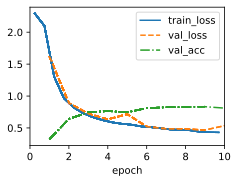

In [ ]:
import torch
from torch import nn
from d2l import torch as d2l


class SharedMLP(d2l.Classifier):
    def __init__(self, lr=0.05):
        super().__init__()
        SharedLayer = nn.LazyLinear(128)
        self.net = nn.Sequential(nn.Flatten(),
                                 nn.LazyLinear(128), nn.ReLU(),
                                 SharedLayer,        nn.ReLU(),
                                 nn.LazyLinear(128), nn.ReLU(),
                                 SharedLayer,        nn.ReLU(),
                                 nn.LazyLinear(10))
        self.lr = lr
    
    def forward(self, X):
        return self.net(X)
    
model = SharedMLP()
data = d2l.FashionMNIST(batch_size=256)
trainer = d2l.Trainer(max_epochs=10)
trainer.fit(model, data)

In [105]:
print(model.net[3].weight.data[0] == model.net[7].weight.data[0])

tensor([True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, True, True, True, True, True, True, True,
        True, True, True, True, True, True, True, True])


Exercise #3

Benefits of parameter sharing would be:
* Impose certain invariances/symmetries (if appropriate/justified)
* Regularization IG / decrease model complexity
* Reduce memory? (by model size?)

# 6.3 Parameter Initialization

* Previously explored in Section 5.4 Numerical Stability & Initalization 
* PyTorch provides default random initialization to its layers
* However, often we may wish to initialize weights according to other protocols, many of which are built into the framework
* Possible to create custom initializers
* By Default: Initializes by drawinf from range computed based on dimensions: https://docs.pytorch.org/docs/2.12/generated/torch.nn.Linear.html?utm_source=chatgpt.com
    * $k = \frac{1}{ \text{input feature dim} }$
    * Weights: $\mathcal{U}(-\sqrt{k}, \sqrt{k})$
    * Bias:    $\mathcal{U}(-\sqrt{k}, \sqrt{k})$

In [108]:
import torch
from torch import nn

net = nn.Sequential(nn.LazyLinear(8), nn.ReLU(), nn.LazyLinear(1))
X = torch.rand(size=(2, 4))
net(X).shape

torch.Size([2, 1])

### 6.3.1 Built-in Initialization

Code below specified to initialize all weight parameters as Gaussian random variabels with std=0.01. Bias parameters set to 0

In [110]:
def init_normal(module):
    if type(module) == nn.Linear:
        nn.init.normal_(module.weight, mean=0, std=0.01)
        nn.init.zeros_(module.bias)

net.apply(init_normal)
net[0].weight.data[0], net[0].bias.data[0] # Pick out the first element ( nn.LazyLinear(8) )

(tensor([-1.3394e-02,  4.4336e-05,  1.2985e-02,  1.5730e-02]), tensor(0.))

In [ ]:
# Can initialize all parameters to given constant value (1 in this case)

def init_constant(module):
    if type(module) == nn.Linear:
        nn.init.constant_(module.weight, 1)
        nn.init.zeros_(module.bias)

net.apply(init_constant)
net[0].weight.data[0], net[0].bias.data[0]

(tensor([1., 1., 1., 1.]), tensor(0.))

In [112]:
# Initialize 1st layer with Xavier and 2nd layer with constant value of 42

def init_xavier(module):
    if type(module) == nn.Linear:
        nn.init.xavier_uniform_(module.weight)

def init_42(module):
    if type(module) == nn.Linear:
        nn.init.constant_(module.weight, 42)

net[0].apply(init_xavier)
net[2].apply(init_42)
print(net[0].weight.data[0])
print(net[2].weight.data)

tensor([-0.3074, -0.2305,  0.5363,  0.6957])
tensor([[42., 42., 42., 42., 42., 42., 42., 42.]])


NOTE: It is possible to defined custom initialization methods. Demo below is for any weight parameter $w$ that can be drawin from the distribution: 
$$
w \sim 
\begin{cases} 
U(5, 10) & \text{with probability } \frac{1}{4} \\
0 & \text{with probability } \frac{1}{2} \\
U(-10, -5) & \text{with probability } \frac{1}{4}

\end{cases}
$$

In [ ]:
def my_init(module):
    if type(module) == nn.Linear:
        print("Init", *[(name, param.shape) for name, param in module.named_parameters()][0])
        nn.init.uniform_(module.weight, -10, 10)
        module.weight.data *= module.weight.data.abs() >= 5

net.apply(my_init)
net[0].weight[:2]

Init weight torch.Size([8, 4])
Init weight torch.Size([1, 8])


tensor([[ 0.0000, -5.4199, -0.0000, -0.0000],
        [-7.4448, -8.9971, -0.0000,  0.0000]], grad_fn=<SliceBackward0>)

In [114]:
# Option of setting parameters directly 

net[0].weight.data[:] += 1
net[0].weight.data[0, 0] = 42
net[0].weight.data[0]

tensor([42.0000, -4.4199,  1.0000,  1.0000])

### 6.3.2 Summary

Introduction to various built-in parameter initializers, along with ability to define custom initializers

### 6.3.3 Exercises
Look up the online documentation for more built-in initializers.

Done: https://docs.pytorch.org/docs/2.12/nn.init.html

# 6.4 Lazy Initialization

So far:
* We defined network architecturse without specifying input dimensionality (e.g. nn.LazyLinear)
* We added layers without specifying the output dimensino of previous layer
* We initialized parametrs before providing enough information on hoy many parameters our models should contain 

* The framework defers initializtion until the first time we pass data through the model and infers sizes of layers, dimension, etc. on the fly. 

Following sections will explore mechanics of initializaton. 

In [116]:
import torch
from torch import nn
from d2l import torch as d2l

net = nn.Sequential(nn.LazyLinear(256), nn.ReLU(), nn.LazyLinear(10))

In [ ]:
# Unintialized parameter since nothing has been passed through yet, so deferring initialization  
net[0].weight

<UninitializedParameter>

In [ ]:
# Once data has been passed through, parameters are initialized and accessible
X = torch.rand(2, 20)
net(X)

net[0].weight.shape

torch.Size([256, 20])

In [119]:
# Following method is for passing a dummy input through the network to infer all parameter shapes, 
# and then perform parameter initialization using init function passed as argument
@d2l.add_to_class(d2l.Module)  
def apply_init(self, inputs, init=None):
    self.forward(*inputs)
    if init is not None:
        self.net.apply(init)

### 6.4.1 Summary

Notes on lazy initialization 

### 6.4.2 Exercises
1. What happens if you specify the input dimensions to the first layer but not to subsequent layers? Do you get immediate initialization?
1. What happens if you specify mismatching dimensions?
1. What would you need to do if you have input of varying dimensionality? Hint: look at the parameter tying.

Exercise #1

Yes, you get immediate initialization since for say smth like nn.LazyLinear, you still have to specify the output and since the initial input dimensions have been specified, all the dimensions can be inferred. 

Exercise #2

Will get an error that attempted matrix multiplication dosen't work due to mistmatching dimensions

Exercise #3

* Perhaps force a reshape at the input layer? (e.g. image resolutions)
* Maybe if appropriate, recurrence/attention is flexible w.r.t. input length. Use a neural network building block that is flexible w.r.t. dimensions of inputs

# 6.5 Custom Layers

There will probably be a point where I need a neural network component/module that is not yet built into PyTorch alr. Have to create my own. 

### 6.5.1 Layers without Parameters

Start by constructing a custom layer that does not have any parameters of its own. 

In [121]:
class CenteredLayer(nn.Module):
    """
    A simple layer that centers the input tensor by subtracting its mean.
    """
    def __init__(self):
        super().__init__()

    def forward(self, X):
        return X - X.mean()
    
# Test it out
layer = CenteredLayer()
tensor = torch.tensor([1.0, 2, 3, 4, 5])
print("mean is: ", tensor.mean())
layer(tensor)

mean is:  tensor(3.)


tensor([-2., -1.,  0.,  1.,  2.])

### 6.5.2 Layers with Parameters

Implement own version of fully-connected layer

In [169]:
class MyFCLayer(nn.Module):
    def __init__(self, in_units, out_units):
        super().__init__()
        self.weight = nn.Parameter(torch.randn(in_units, out_units))
        self.bias = nn.Parameter(torch.zeros(out_units))

    def forward(self, X):
        linear = torch.matmul(X, self.weight.data) + self.bias.data
        return F.relu(linear)
    
linear = MyFCLayer(5, 3)
linear.weight

Parameter containing:
tensor([[ 2.4691, -0.3237, -0.4053],
        [ 0.2420,  0.1114, -0.3555],
        [ 1.3478, -1.0857,  0.4488],
        [-0.9314,  1.4101,  0.2339],
        [ 0.6348, -0.2510,  0.1139]], requires_grad=True)

In [172]:
# Use as part of larger network
net = nn.Sequential(MyFCLayer(64, 8), MyFCLayer(8, 1))
net(torch.rand(2, 64))

tensor([[0.0000],
        [5.4197]])

### 6.5.3 Summary

How to design custom layers/modules/components

### 6.5.4 Exercises
1. Design a layer that takes an input and computes a tensor reduction,
   i.e., it returns $y_k = \sum_{i, j} W_{ijk} x_i x_j$.
1. Design a layer that returns the leading half of the Fourier coefficients of the data.

Exercise #1

In [ ]:
# Initial Try - IGNORE
# Issues:
# 1. torch.matmul only takes 2 arguments
# 2. IDT it really matters if in forward method, self.weight.data is used or just self.weight. 
#  Section 6.5.2 above uses self.weight.data, but example from PyTorch website uses 
#  self.parameter (no .data) in forward method: https://docs.pytorch.org/tutorials/beginner/examples_nn/polynomial_module.html 
# 3. Don't specify the inputs for the forward method within the class __init__ method.
# 4. Misinterpreted as two separate inputs, reading exercise statement, it says "an input"
class TensorReduction(nn.Module):
    def __init__(self, x1, x2, k: int):
        super().__init__()
        self.x1 = x1
        self.x2 = x2
        self.k  = k
        self.weight = nn.Parameter(torch.randn( len(self.x1), len(self.x2), int(self.k) ))

    def forward(self, X):
        return torch.matmul(self.weight.data, self.x1, self.x2)


In [187]:
# Attempt 2
class TensorReduction(nn.Module):
    def __init__(self, in_units: int, out_units: int):
        super().__init__()
        self.weight = nn.Parameter(torch.randn( in_units, in_units, out_units) )

    def forward(self, X):
        return torch.einsum('ijk, i, j -> k', self.weight, X, X)
    
in_units = 4
out_units = 3

layer = TensorReduction(in_units, out_units)

X = torch.randn(in_units)

Y = layer(X)

print("X shape:", X.shape)
print("weight shape:", layer.weight.shape)
print("Y shape:", Y.shape)


X shape: torch.Size([4])
weight shape: torch.Size([4, 4, 3])
Y shape: torch.Size([3])


torch.einsum: https://docs.pytorch.org/docs/2.12/generated/torch.einsum.html

In [ ]:
# Trace of square matrix
torch.einsum('ii' , torch.arange(9).reshape(3, 3))
# 0 1 2
# 3 4 5
# 6 7 8

tensor(12)

In [ ]:
# Extract diagonal elements of square matrix
torch.einsum('ii->i', torch.arange(16).reshape(4, 4))

tensor([ 0,  5, 10, 15])

In [186]:
x = torch.arange(6)
y = torch.arange(4)
torch.einsum('i,j->ij', x, y), torch.matmul(x.reshape(-1, 1), y.reshape(1, -1))

(tensor([[ 0,  0,  0,  0],
         [ 0,  1,  2,  3],
         [ 0,  2,  4,  6],
         [ 0,  3,  6,  9],
         [ 0,  4,  8, 12],
         [ 0,  5, 10, 15]]),
 tensor([[ 0,  0,  0,  0],
         [ 0,  1,  2,  3],
         [ 0,  2,  4,  6],
         [ 0,  3,  6,  9],
         [ 0,  4,  8, 12],
         [ 0,  5, 10, 15]]))

In [145]:
x1 = torch.tensor([1.0, 2, 3])
len(x1)

3

Exercise #2

No learnable parameters layer. Already seems to be torch.fft module. 

Skip

# 6.6 File I/O

* May want to save results of learned models for use later (say, predictions in deployment)
* When running long training processes, good practice to periodically save intermediate results (checkpointing)
* Will cover how to load/astore individual weight vectors and entire models

In [188]:
import torch
from torch import nn
from torch.nn import functional as F

### 6.6.1 Loading and Saving Tensors

* Can directly invoke _load_ and _save_ functions to read/write respectivly.
* Requires us we supply a name, and _save_ requires as input the variable to be saved

In [ ]:
# Save tensor to File
x = torch.arange(4)
# Saves to same directory this Jupyter Notebook file is in. It a "File" format
torch.save(x, 'x-file')

In [ ]:
# Load back tensor from memory
x2 = torch.load('x-file')
x2

tensor([0, 1, 2, 3])

In [191]:
# Store a list of tensors and read them back into memory
y = torch.zeros(4)
torch.save([x, y],'x-files')
x2, y2 = torch.load('x-files')
(x2, y2)

(tensor([0, 1, 2, 3]), tensor([0., 0., 0., 0.]))

In [192]:
# Can write and read a dictionary that maps from strings to tensors. Convinent when we 
# want to read/write all weights in a model
mydict = {'x': x, 'y': y}
torch.save(mydict, 'mydict')
mydict2 = torch.load('mydict')
mydict2

{'x': tensor([0, 1, 2, 3]), 'y': tensor([0., 0., 0., 0.])}

### 6.6.2 Loading and Saving Model Parameters

NOTE: Framework's built-in functionalities to save/load entire networks is only for _parameters_, and not the entire model. The model's architecture needs to be specified separately. This is because models themselves have arbitrary code and cannot be serialized as naturally. 

If we want to load a saved model, have to generate architecture in code, and then load in the previously learned parameters from the disk. 

In [193]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = nn.LazyLinear(256)
        self.out    = nn.LazyLinear(10)

    def forward(self, X):
        return self.out(F.relu(self.hidden(X)))

net = MLP()
X = torch.randn(size=(2, 20))
Y = net(X)

In [ ]:
# Save the model's parameters
torch.save(net.state_dict(), 'mlp.params')

In [195]:
# Recoveringn original model
# Create another instance of same class
# Instead of initializing, load in parameters from saved file
clone = MLP()
clone.load_state_dict(torch.load('mlp.params'))
clone.eval()

MLP(
  (hidden): LazyLinear(in_features=0, out_features=256, bias=True)
  (out): LazyLinear(in_features=0, out_features=10, bias=True)
)

In [ ]:
# Test if both models are the same by passing in random input
Y_clone = clone(X)
Y_clone == Y

tensor([[True, True, True, True, True, True, True, True, True, True],
        [True, True, True, True, True, True, True, True, True, True]])

### 6.6.3 Summary

* Can save/load both individual tensors, and entire models
* Keep in mind, cannot save the model architecture to disk, only the parameters
* Therefore, need to create an another instance of model in question and then load in parameters from saved file

### 6.6.4 Exercises

1. Even if there is no need to deploy trained models to a different device, what are the practical benefits of storing model parameters?
1. Assume that we want to reuse only parts of a network to be incorporated into a network having a different architecture. How would you go about using, say the first two layers from a previous network in a new network?
1. How would you go about saving the network architecture and parameters? What restrictions would you impose on the architecture?


Exercise #1

* For long training runs, if they happen to be interrupted, all progress isn't lost due to technical issues

Exercise #2

* Load new archiecture
* Load in desired saved parameters from previous network into now sub-network 
* Freeze weights by turing gradients off while training the rest of the new, larger architecture 

Exercise #3 

Just same method as before, remember/note what class the new architecture was from and the corresponding parameter file, saved according to methods above. 

# 6.7 GPUs

* In PyTorch, every array has a device which is referred to as "context"
* By default, all variables and associated computation is assigned to CPU
* By assigning arrays to contexts intelligently, we can minimize data transfer time (e.g. typically prefer to keep model's parameters on the GPU)

NOTE: Many/All code here requires at least 2 GPUs. So just study/reference syntax. Not actually gonna run anything here on my end

### 6.7.1 Computing Devices

* By Default, create on main memory and use CPU for calculations
* cpu Device refers to all physical CPUs and memory, in that PyTOrch will try to use ALL cpu cores
* gpu device only represents 1 card and its corresponding memory
* Note: 'gpu:0' and 'gpu' are equivalent 

In [200]:
def cpu():
    return torch.device('cpu')

def gpu(i=0):
    return torch.device(f'cuda:{i}')

cpu(), gpu(), gpu(1), gpu(2)

(device(type='cpu'),
 device(type='cuda', index=0),
 device(type='cuda', index=1),
 device(type='cuda', index=2))

In [ ]:
def num_gpus():  
    """Get the number of available GPUs."""
    return torch.cuda.device_count()

num_gpus()

1

In [203]:
def try_gpu(i=0):  
    """Return gpu(i) if exists, otherwise return cpu()."""
    if num_gpus() >= i + 1:
        return gpu(i)
    return cpu()

def try_all_gpus():  
    """Return all available GPUs, or [cpu(),] if no GPU exists."""
    return [gpu(i) for i in range(num_gpus())]

try_gpu(), try_gpu(10), try_all_gpus()

(device(type='cuda', index=0),
 device(type='cpu'),
 [device(type='cuda', index=0)])

### 6.7.2 Tensors and GPUs

* By default, tensors are created on the CPU
* We can look up where tensor is located
* If we want to perform operations on multiple terms, they must be on the same device

In [204]:
x = torch.tensor([1, 2, 3])
x.device

device(type='cpu')

In [205]:
X = torch.ones(2, 3, device=try_gpu())
X

tensor([[1., 1., 1.],
        [1., 1., 1.]], device='cuda:0')

In [ ]:
# If I had two GPU's would show device='cuda:1'
# Probably on CPU. CHeck below
Y = torch.rand(2, 3, device=try_gpu(1))
Y

tensor([[0.4485, 0.7218, 0.1877],
        [0.9812, 0.2711, 0.4727]])

In [207]:
Y.device

device(type='cpu')

Can also copy data from 1 device to another

### 6.7.3 Neural Networks and GPUs

Neural network model can specify devices

In [210]:
# Following code puts model parameters on GPU
net = nn.Sequential(nn.LazyLinear(1))
net = net.to(device=try_gpu())

# Test
net(X)

tensor([[0.2793],
        [0.2793]], device='cuda:0', grad_fn=<AddmmBackward0>)

### 6.7.4 Summary

### 6.7.5 Exercises
1. Try a larger computation task, such as the multiplication of large matrices,
   and see the difference in speed between the CPU and GPU.
   What about a task with a small number of calculations?
1. How should we read and write model parameters on the GPU?
1. Measure the time it takes to compute 1000
   matrix--matrix multiplications of $100 \times 100$ matrices
   and log the Frobenius norm of the output matrix one result at a time. Compare it with keeping a log on the GPU and transferring only the final result.
1. Measure how much time it takes to perform two matrix--matrix multiplications
   on two GPUs at the same time. Compare it with computing in in sequence
   on one GPU. Hint: you should see almost linear scaling.

Exercise #1

I used GPT for this

In [ ]:
import torch
import time

def benchmark_matmul(n, device, repeats=50, warmup=10):
    A = torch.randn(n, n, device=device)
    B = torch.randn(n, n, device=device)
    # Warmup: especially important for GPU
    for _ in range(warmup):
        C = A @ B

    if device == "cuda":
        torch.cuda.synchronize()
    start = time.time()

    for _ in range(repeats):
        C = A @ B

    if device == "cuda":
        torch.cuda.synchronize()
    end = time.time()
    return (end - start) / repeats

sizes = [8, 32, 128, 512, 1024, 2048, 4096]

devices = ["cpu", "cuda"]

for n in sizes:
    print(f"\nMatrix size: {n} x {n}")
    for device in devices:
        t = benchmark_matmul(n, device)
        print(f"{device}: {t * 1000:.4f} ms")


Matrix size: 8 x 8
cpu: 0.0000 ms
cuda: 0.8414 ms

Matrix size: 32 x 32
cpu: 0.0200 ms
cuda: 0.0762 ms

Matrix size: 128 x 128
cpu: 0.1500 ms
cuda: 0.0200 ms

Matrix size: 512 x 512
cpu: 0.4104 ms
cuda: 0.1002 ms

Matrix size: 1024 x 1024
cpu: 2.2670 ms
cuda: 0.7805 ms

Matrix size: 2048 x 2048
cpu: 17.2822 ms
cuda: 3.6215 ms

Matrix size: 4096 x 4096
cpu: 123.1227 ms
cuda: 5.2604 ms


Exercise #2

Move model, then parameters to GPU. Read/write/train as normal (same as before)

Exercise #3

In [272]:
# Move one per iteration 

torch.cuda.synchronize()
start = time.time()

norms = []

for i in range(1000):
    matA = torch.randn(1000, 1000, device='cuda:0')
    matB = torch.randn(1000, 1000, device='cuda:0')
    matAmatB = matA @ matB
    norm = torch.norm(matAmatB, p='fro', keepdim=True)
    norms.append(norm)

norms = torch.tensor(norms, device='cpu')

torch.cuda.synchronize()
end = time.time()

print("Total Time for move every iter: {:.4f} seconds".format(end - start))

# Move all at once at end

torch.cuda.synchronize()
start = time.time()

norms = torch.empty(1000, device='cuda:0')
for i in range(1000):
    matA = torch.randn(1000, 1000, device='cuda:0')
    matB = torch.randn(1000, 1000, device='cuda:0')
    matAmatB = matA @ matB
    norm = torch.norm(matAmatB, p='fro', keepdim=True)
    norms[i] = norm

norms = norms.to('cpu')

torch.cuda.synchronize()
end = time.time()

print("Total Time for move all at once: {:.4f} seconds".format(end - start))

Total Time for move every iter: 0.3523 seconds
Total Time for move all at once: 0.1178 seconds


Exercise #4

Skip. I only have 1 GPU available on this system. 